# 14 The final test on the 20 locked products
Since the start, 20 of my 50 test products have been locked: I never rated their results, used them in tuning, or looked at them. All the weights and settings were chosen with the other 30 (the development products). This notebook is the one honest test of the finished search on products it has never seen. The search, the weights and the code were final before I made the rating page, and nothing was changed after I saw the result. This test is used once.

In [1]:
import json
import os
from pathlib import Path

import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(root)
pd.set_option("display.width", 200)

scores = json.loads((root / "results" / "final_test_scores.json").read_text(encoding="utf-8"))
coverage = json.loads((root / "results" / "final_test_coverage.json").read_text(encoding="utf-8"))
print("loaded the saved results")

loaded the saved results


## 1. How the test was done
1. **The search.** The final search in both modes: the exact mode, and the fast mode (HNSW, the 100 nearest products from each of the two indexes). The same code and weights as in the service. No product is hidden.
2. **The pool.** For each of the 20 locked products, the top 10 of both modes were put together and shuffled into one blind page: 204 results in all, with no method names (`experiments/run_final_test_rating.py`). The two modes overlap, so there are a little over 10 results for each product.
3. **My ratings.** I rated every result 0, 1 or 2, with the same rules as before (`evaluation/rubric.md`). They are in `evaluation/judgments/final_grades.csv`.
4. **The score.** My ratings are the truth: for each mode I took its own top 10 and computed nDCG@10 and precision@10 (`experiments/score_final_test.py`). Time is the whole search, 5 runs per product, the fastest kept, the median of the 20 products, one thread.

In [2]:
print("products:", coverage["products"], "| results rated:", coverage["results_to_rate"])
rows = []
for mode, m in scores["modes"].items():
    rows.append(
        {
            "mode": mode,
            "nDCG@10": m["ndcg_at_10"],
            "precision@10": m["precision_at_10"],
            "time per search (ms)": m["ms_per_search"],
            "rated 2": m["rated_2"],
            "rated 1": m["rated_1"],
            "rated 0": m["rated_0"],
        }
    )
display(pd.DataFrame(rows).set_index("mode"))

products: 20 | results rated: 204


,nDCG@10,precision@10,time per search (ms),rated 2,rated 1,rated 0
mode,,,,,,
exact,0.9659,0.87,7.032,165,9,26
fast,0.9657,0.87,0.417,165,9,26


### What this shows
Both modes give the same quality on products they have never seen: precision@10 is 0.87 for both, close to the 0.877 on the development products. Of the 200 results each mode returns (10 for each of the 20 products), I rated 165 with a 2 (very similar), 9 with a 1 and 26 with a 0. The fast mode is about 17 times faster (0.42 ms against 7.0 ms).

## 2. Product by product
The nDCG@10 and the precision@10 of each locked product, for both modes. A product has no nDCG@10 when none of its pooled results was rated above 0.

In [3]:
rows = []
for no, v in scores["per_product"].items():
    rows.append(
        {
            "product": no,
            "nDCG exact": v["exact"]["ndcg"],
            "nDCG fast": v["fast"]["ndcg"],
            "precision exact": v["exact"]["precision"],
            "precision fast": v["fast"]["precision"],
        }
    )
table = pd.DataFrame(rows).set_index("product")
display(table)
p = scores["per_product_ndcg"]
print(
    f"same nDCG@10 in both modes: {p['same_in_both_modes']} products; fast lower: {p['fast_lower']}; fast higher: {p['fast_higher']}",
    p["differing"],
)

,nDCG exact,nDCG fast,precision exact,precision fast
product,,,,
Q03,1.0000,1.0000,1.0,1.0
Q05,1.0000,1.0000,1.0,1.0
Q08,1.0000,1.0000,1.0,1.0
Q10,1.0000,1.0000,1.0,1.0
Q13,0.9511,0.9511,1.0,1.0
Q15,1.0000,1.0000,1.0,1.0
Q18,0.9196,0.9196,0.9,0.9
Q20,0.9897,0.9897,1.0,1.0
Q23,0.9066,0.9066,0.3,0.3


same nDCG@10 in both modes: 18 products; fast lower: 1; fast higher: 0 {'Q33': {'exact': 0.7959, 'fast': 0.7925}}


### What this shows
For 18 of the 19 products that have something to find, the two modes have exactly the same nDCG@10. Only Q33 differs, a little (0.7959 for the exact mode, 0.7925 for the fast mode). The weak spots are the same for both modes. For Q48, neither mode found anything similar: all 10 results were rated 0. Q23 (3 of 10 results rated above 0) and Q43 (5 of 10) have a low precision.

## 3. How to read the nDCG@10 here
The nDCG@10 is 0.97 here against 0.81 on the development products, but the two cannot be compared. nDCG compares a ranking with the best ranking possible from the rated results. On the development products the rated results came from many methods (title, pictures, attributes, the hybrid), so the best possible ranking contained better results that the hybrid sometimes missed. Here the rated results come only from the two modes of the final search, which return almost the same products, so there is nothing better to compare with, and nDCG is high by construction. **Precision@10 does not depend on the pool**, so it is the number to compare: 0.87 on the locked products and 0.877 on the development products. The search holds up on products it has never seen.

## 4. Recorded in MLflow
Each mode is a run in the experiment `final-test` (2 runs), with its nDCG@10, precision@10, time and the counts of results rated 2, 1 and 0:

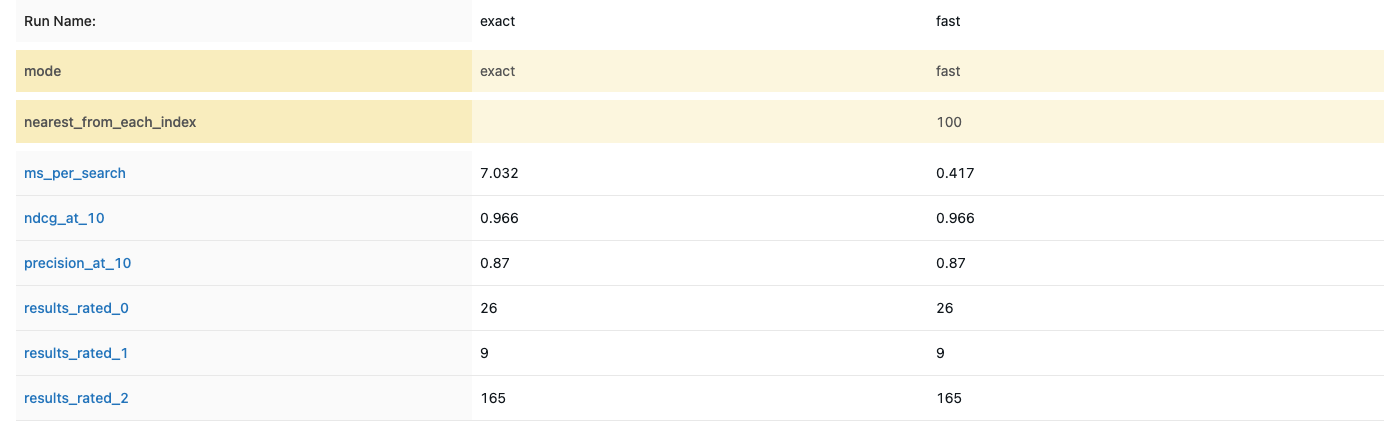

In [4]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_final_test_runs.png", width=800)

## 5. Conclusion

**What I did.** I tested the finished search once, on the 20 products that were locked from the start. I rated the top 10 results of both modes (exact and fast), 204 results in all, and scored each mode from my ratings.

| 20 locked products | nDCG@10 | Precision@10 | Time per search |
|---|---|---|---|
| Exact mode | 0.9659 | 0.87 | 7.0 ms |
| Fast mode (HNSW) | 0.9657 | 0.87 | 0.42 ms |

**What I found.** On products it had never seen, both modes work: precision@10 is 0.87 for both, close to 0.877 on the development products. The fast mode gives the same quality and is about 17 times faster.

**Limitation.** The nDCG@10 here (0.97) cannot be compared with 0.81 on the development products, because the rated results come only from this one system. Precision@10 is the number to compare. It is only 20 products, rated by me, and the test was used once.

**What I do next.** The stronger API, then Kubernetes and CI/CD, then the page, and the final cleanup.